# 06 Evaluate: do the extra data help?

**Purpose:** Compare the models with the extra data blocks (`05b`, `05c`) with the same models without them (`02b`), in the units and with the rules of `03_evaluate.ipynb`: MAE in persons, main horizon $h = 2$, year by year, without the crisis periods, and the success rule of our plan. We also add a third simple rule, the last known month.
**Input:** `../data/processed/backtest_forecasts.csv`, `backtest_forecasts_regression.csv`, `backtest_forecasts_extra.csv`, `backtest_forecasts_lag_choice.csv`, `asylum_clean.csv` and `test_forecasts.csv`.
**Output:** `../output/tables/06_extra_errors.csv`, `06_extra_effect.csv`, `06_extra_by_year_h2.csv`, `06_random_walk.csv` and two figures in `../output/figures/`.

**The test period was used once, in `04_test.ipynb`, and our chosen model stays the linear regression.** Everything here is a secondary analysis on the backtest. Only section 3 looks at the test period, for the new simple rule, and says so.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

The same two errors as in `03`: the absolute error in persons and the squared error in logs. We add the forecasts of the **random walk**: the forecast for every horizon is the last known month, $\hat y_{t+h} = y_t$. It is the simplest rule a planner could use ("next months like the last one"), and it was missing from our baselines. We add it now, after the test, and say so; it does not change our choice.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

def read(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    data["origin"] = pd.to_datetime(data["origin"])
    return data

cols = ["model", "origin", "month", "h", "forecast_log", "actual_log", "forecast", "actual"]
base = pd.concat([read("../data/processed/backtest_forecasts.csv")[cols],
                  read("../data/processed/backtest_forecasts_regression.csv")[cols]], ignore_index=True)
extra = read("../data/processed/backtest_forecasts_extra.csv")
lag_choice = read("../data/processed/backtest_forecasts_lag_choice.csv")

# Random walk: the same origins and horizons as the other models
rw = base[base["model"] == "Linear regression"].copy()
rw["model"] = "Random walk"
rw["forecast"] = clean.loc[rw["origin"], "applicants_total"].to_numpy()
rw["forecast_log"] = clean.loc[rw["origin"], "log_applicants"].to_numpy()

forecasts = pd.concat([base, rw, extra[cols], lag_choice[cols]], ignore_index=True)
forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

counts = forecasts.groupby(["model", "h"]).size().unstack()
print("Models:", forecasts["model"].nunique(), "| forecasts per model and horizon:", counts.drop_duplicates().to_dict("records"))
print("Same forecast months for all models:",
      forecasts.groupby(["model", "h"])["month"].apply(lambda m: tuple(sorted(m))).groupby("h").nunique().eq(1).all())

Models: 24 | forecasts per model and horizon: [{1: 141, 2: 140, 3: 139}]
Same forecast months for all models: True


## 2. Errors of all models

`error_table` is copied from `03`.

In [3]:
simple_rules = ["Seasonal naive", "12-month average", "Random walk"]
sarima_models = ["ARIMA(1,1,0)", "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]
regression_models = ["Linear regression", "Ridge", "Lasso"]
blocks = ["neighbours", "Med routes", "conflict", "all three"]
block_models = [f"{m} + {bl}" for bl in blocks for m in regression_models]
lag_models = sorted(lag_choice["model"].unique())
model_order = simple_rules + sarima_models + regression_models + block_models + lag_models

def error_table(data):
    # MAE in persons and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)
mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]
overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/06_extra_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
Random walk,259.0,379.0,487.0,0.195,0.288,0.358
"ARIMA(1,1,0)",272.0,388.0,499.0,0.207,0.292,0.361
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.199,0.282,0.347
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Lasso,254.0,360.0,450.0,0.193,0.281,0.338


**What we see.**
- All 24 models have the same 141, 140 and 139 forecast months, so the comparison is fair (notebook 209).
- **The random walk is a strong simple rule:** 379 persons at $h = 2$, far better than the 12-month average (528) and the seasonal naive (681), and close to the own-history models (358 to 371). At $h = 1$ it is even better than ARIMA(1,1,0) (259 against 272).
- **With extra data**, the lowest MAE at $h = 2$ is Ridge + Med routes (341), then Ridge + all three (342). The three regressions with the neighbours (361 to 372) and Lasso / the linear regression with the conflict index (360 to 362) are not better than the models without extra data (358 to 360).
- By RMSE (log) the differences are even smaller: Ridge + Med routes has 0.272 against 0.274 for the best SARIMA and 0.278 for the linear regression.

## 3. A third simple rule: the last known month

Our plan's main comparison is the best simple baseline against the best model, at $h = 2$ (Johannes' feedback). With the random walk as a third simple rule, which one is the best simple baseline, and does our chosen model still meet the success rule (at least 10% lower MAE and a win in most backtest years)?

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year
by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.columns.name = None

def compare(a, b):
    # a against b at h = 2: change in MAE, wins year by year, gap of the averages, spread across years
    change = 100 * (h2.loc[a, "MAE (persons)"] / h2.loc[b, "MAE (persons)"] - 1)
    wins = int((by_year[a] < by_year[b]).sum())
    return {"model": a, "against": b, "MAE": round(h2.loc[a, "MAE (persons)"]), "MAE against": round(h2.loc[b, "MAE (persons)"]),
            "change in MAE (%)": round(change, 1), "years won (of 12)": wins,
            "gap of the yearly averages": round(by_year[b].mean() - by_year[a].mean()),
            "spread across years (std of b)": round(by_year[b].std()),
            "success rule met": bool(change <= -10 and wins > by_year.shape[0] / 2)}

rw_table = pd.DataFrame([compare("Linear regression", b) for b in simple_rules]).set_index("against")
rw_table.to_csv("../output/tables/06_random_walk.csv")
rw_table

,model,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
against,,,,,,,,
Seasonal naive,Linear regression,358,681,-47.4,11,323,467,True
12-month average,Linear regression,358,528,-32.2,9,167,417,True
Random walk,Linear regression,358,379,-5.4,7,19,237,False


**The random walk in the test period.** The same rule, at the 23 test origins of `04_test.ipynb` (no model to fit, so nothing is chosen here; we only add a row to the test table).

In [5]:
test = read("../data/processed/test_forecasts.csv")
test_rw = test[test["model"] == "Linear regression"].copy()
test_rw["model"] = "Random walk"
test_rw["forecast"] = clean.loc[test_rw["origin"], "applicants_total"].to_numpy()
test_all = pd.concat([test, test_rw], ignore_index=True)
test_all["abs_error"] = (test_all["actual"] - test_all["forecast"]).abs()
test_all.pivot_table(index="model", columns="h", values="abs_error", aggfunc="mean").round(0)

h,1,2,3
model,,,
12-month average,297.0,331.0,359.0
Linear regression,149.0,188.0,217.0
Random walk,187.0,269.0,358.0


**What we see.**
- Against our two planned simple rules, the chosen linear regression meets the success rule clearly: 47% and 32% lower MAE, better in 11 and 9 of the 12 years.
- **Against the random walk it would not:** only 5.4% lower MAE (358 against 379) and better in 7 of 12 years. The gap of the yearly averages (19 persons) is small compared with the spread across years (237).
- In the test period, the random walk misses by 269 applications at $h = 2$, between the linear regression (188) and the 12-month average (331). Here the linear regression is 30% better than the random walk, because the test period has a clear seasonal pattern that the random walk ignores (`04_test`, section 6).

**What this means for us.** Our main result holds against the simple rules we fixed in advance, and in the test period also against the random walk. But in the backtest, most of the gain over the 12-month average comes from starting at the **last known month**, which the 12-month average does not do; the regression adds the seasonal pattern on top. We report this honestly: the random walk was not in our plan, and adding it after the test does not change our choice.

## 4. Does each block help? One block at a time

As in `03`, section 7: each regression against its own version with the block, on the same forecast months, at all horizons.

In [6]:
rows = []
for block in blocks:
    for name in regression_models:
        for h in [1, 2, 3]:
            without = errors[(errors["model"] == name) & (errors["h"] == h)].iloc[0]
            with_block = errors[(errors["model"] == f"{name} + {block}") & (errors["h"] == h)].iloc[0]
            rows.append({"block": block, "model": name, "h": h,
                         "MAE without": without["MAE (persons)"], "MAE with": with_block["MAE (persons)"],
                         "change in MAE (%)": 100 * (with_block["MAE (persons)"] / without["MAE (persons)"] - 1)})
for name in lag_models:
    for h in [1, 2, 3]:
        without = errors[(errors["model"] == "Ridge") & (errors["h"] == h)].iloc[0]
        with_block = errors[(errors["model"] == name) & (errors["h"] == h)].iloc[0]
        rows.append({"block": name.replace("Ridge + ", ""), "model": "Ridge", "h": h,
                     "MAE without": without["MAE (persons)"], "MAE with": with_block["MAE (persons)"],
                     "change in MAE (%)": 100 * (with_block["MAE (persons)"] / without["MAE (persons)"] - 1)})
effect = pd.DataFrame(rows)
effect.to_csv("../output/tables/06_extra_effect.csv", index=False)
effect.pivot_table(index=["block", "model"], columns="h", values="change in MAE (%)", sort=False).round(1)

h                                            1    2    3
block                   model                           
neighbours              Linear regression  3.3  0.9  3.1
                        Ridge             -3.0  2.3  2.7
                        Lasso             -2.2  3.4 -0.0
Med routes              Linear regression  2.6 -1.3  0.8
                        Ridge             -3.0 -4.8 -2.9
                        Lasso             -2.8 -4.0 -1.9
conflict                Linear regression  3.1  0.4  2.4
                        Ridge              0.4 -1.4 -0.5
                        Lasso              2.0  0.4 -0.6
all three               Linear regression  8.4  0.6  4.6
                        Ridge             -1.8 -4.4 -0.3
                        Lasso             -2.2 -2.0  0.8
Med routes (lag chosen) Ridge             -2.2 -3.4 -1.5
conflict (lag chosen)   Ridge              3.8  2.8  1.1
neighbours (lag chosen) Ridge             -0.4  2.3  5.6

**What we see.**
- **Neighbours:** worse at $h = 2$ for all three models (+0.9% to +3.4%); Ridge and Lasso are a little better at $h = 1$ (−3.0% and −2.2%), the horizon where the newest month matters most.
- **Mediterranean routes:** Ridge and Lasso are better at all three horizons (−4.8% and −4.0% at $h = 2$); the linear regression only at $h = 2$ (−1.3%).
- **Conflict index:** small changes in both directions (−1.4% to +3.1%).
- **All three blocks together:** Ridge −4.4% at $h = 2$, about as good as the routes alone; the linear regression gets worse (+8.4% at $h = 1$): with 20 features and no penalty it overfits.
- **Lag chosen in each window:** the routes keep a gain (−3.4% at $h = 2$), the neighbours and the conflict index get worse (+2.3% and +2.8%).
- No change reaches the 10% of our success rule.

## 5. Year by year at $h = 2$, and the success rule

As in `03`, section 5 (notebook 209): the years are our folds. For every model with extra data: in how many of the 12 years is it better than the same model without the block, and is the gap of the averages large compared with the spread across years? The success rule of our plan, fixed before modelling, asks for at least 10% lower MAE **and** a win in most years.

In [7]:
pairs = [(f"{m} + {bl}", m) for bl in blocks for m in regression_models] + [(m, "Ridge") for m in lag_models]
year_table = pd.DataFrame([compare(a, b) for a, b in pairs]).set_index("model")
by_year.to_csv("../output/tables/06_extra_by_year_h2.csv")
year_table.drop(columns=["against"])

,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,
Linear regression + neighbours,361,358,0.9,4,-3,210,False
Ridge + neighbours,366,358,2.3,4,-8,220,False
Lasso + neighbours,372,360,3.4,2,-12,214,False
Linear regression + Med routes,353,358,-1.3,7,5,210,False
Ridge + Med routes,341,358,-4.8,8,17,220,False
Lasso + Med routes,346,360,-4.0,6,15,214,False
Linear regression + conflict,360,358,0.4,6,-2,210,False
Ridge + conflict,353,358,-1.4,8,4,220,False
Lasso + conflict,362,360,0.4,3,-2,214,False


**What we see.**
- The best blocks win in **8 of 12 years**: Ridge + Med routes, Ridge + all three, Ridge + conflict and Ridge + Med routes with the lag chosen. The neighbours win in only 2 to 4 years with the fixed lag.
- **But the gaps are tiny compared with the spread across years:** the largest gap of the yearly averages is 17 persons (Ridge + Med routes), against a spread of about 220. Ridge + conflict wins 8 years with a gap of only 4 persons, so most of its wins are very small.
- **No model meets the success rule** (at least 10% lower MAE and a win in most years): the MAE gains are at most 4.8%.

**What this means for us.** As for the route indicator in `03`, the extra data do not give a clear improvement. The only block with a consistent sign (better at all three horizons for Ridge and Lasso, and in 8 of 12 years) is the Mediterranean routes at the UNHCR timing. We tried about 30 variants in steps F and G, so the best of them looks better than it would on new data (notebook 108b): we treat −4.8% as a hint, not as a result.

## 6. Without the crisis periods

As in `03`, section 4: all backtest months, without 2015-16 and 2020, and from 2022 only ($h = 2$).

In [8]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))
periods = {"all backtest months": forecasts, "without 2015-16 and 2020": forecasts[~crisis],
           "from 2022": forecasts[month >= "2022-01-01"]}
rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)
show = ["Random walk", "Linear regression", "Ridge"] + [f"Ridge + {bl}" for bl in blocks] + lag_models
by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[show, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Random walk,379.0,309.0,488.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Ridge + neighbours,366.0,289.0,429.0
Ridge + Med routes,341.0,270.0,403.0
Ridge + conflict,353.0,278.0,412.0
Ridge + all three,342.0,268.0,385.0
Ridge + Med routes (lag chosen),346.0,277.0,407.0
Ridge + conflict (lag chosen),368.0,293.0,443.0


**What we see.** The ranking is the same in all three periods. Without 2015-16 and 2020, Ridge + all three (268) and Ridge + Med routes (270) are lowest, against 282 for Ridge and 286 for the linear regression. From 2022, Ridge + all three is lowest (385 against 413 for the linear regression, −7%), the largest gain in any period, but over only 33 months. The neighbours and the conflict index with the lag chosen are worse than Ridge in every period.

## 7. The picture

The change in MAE at $h = 2$ for every model with extra data, against the same model without them. Bars to the left mean a lower error. The dashed line marks the 10% of our success rule.

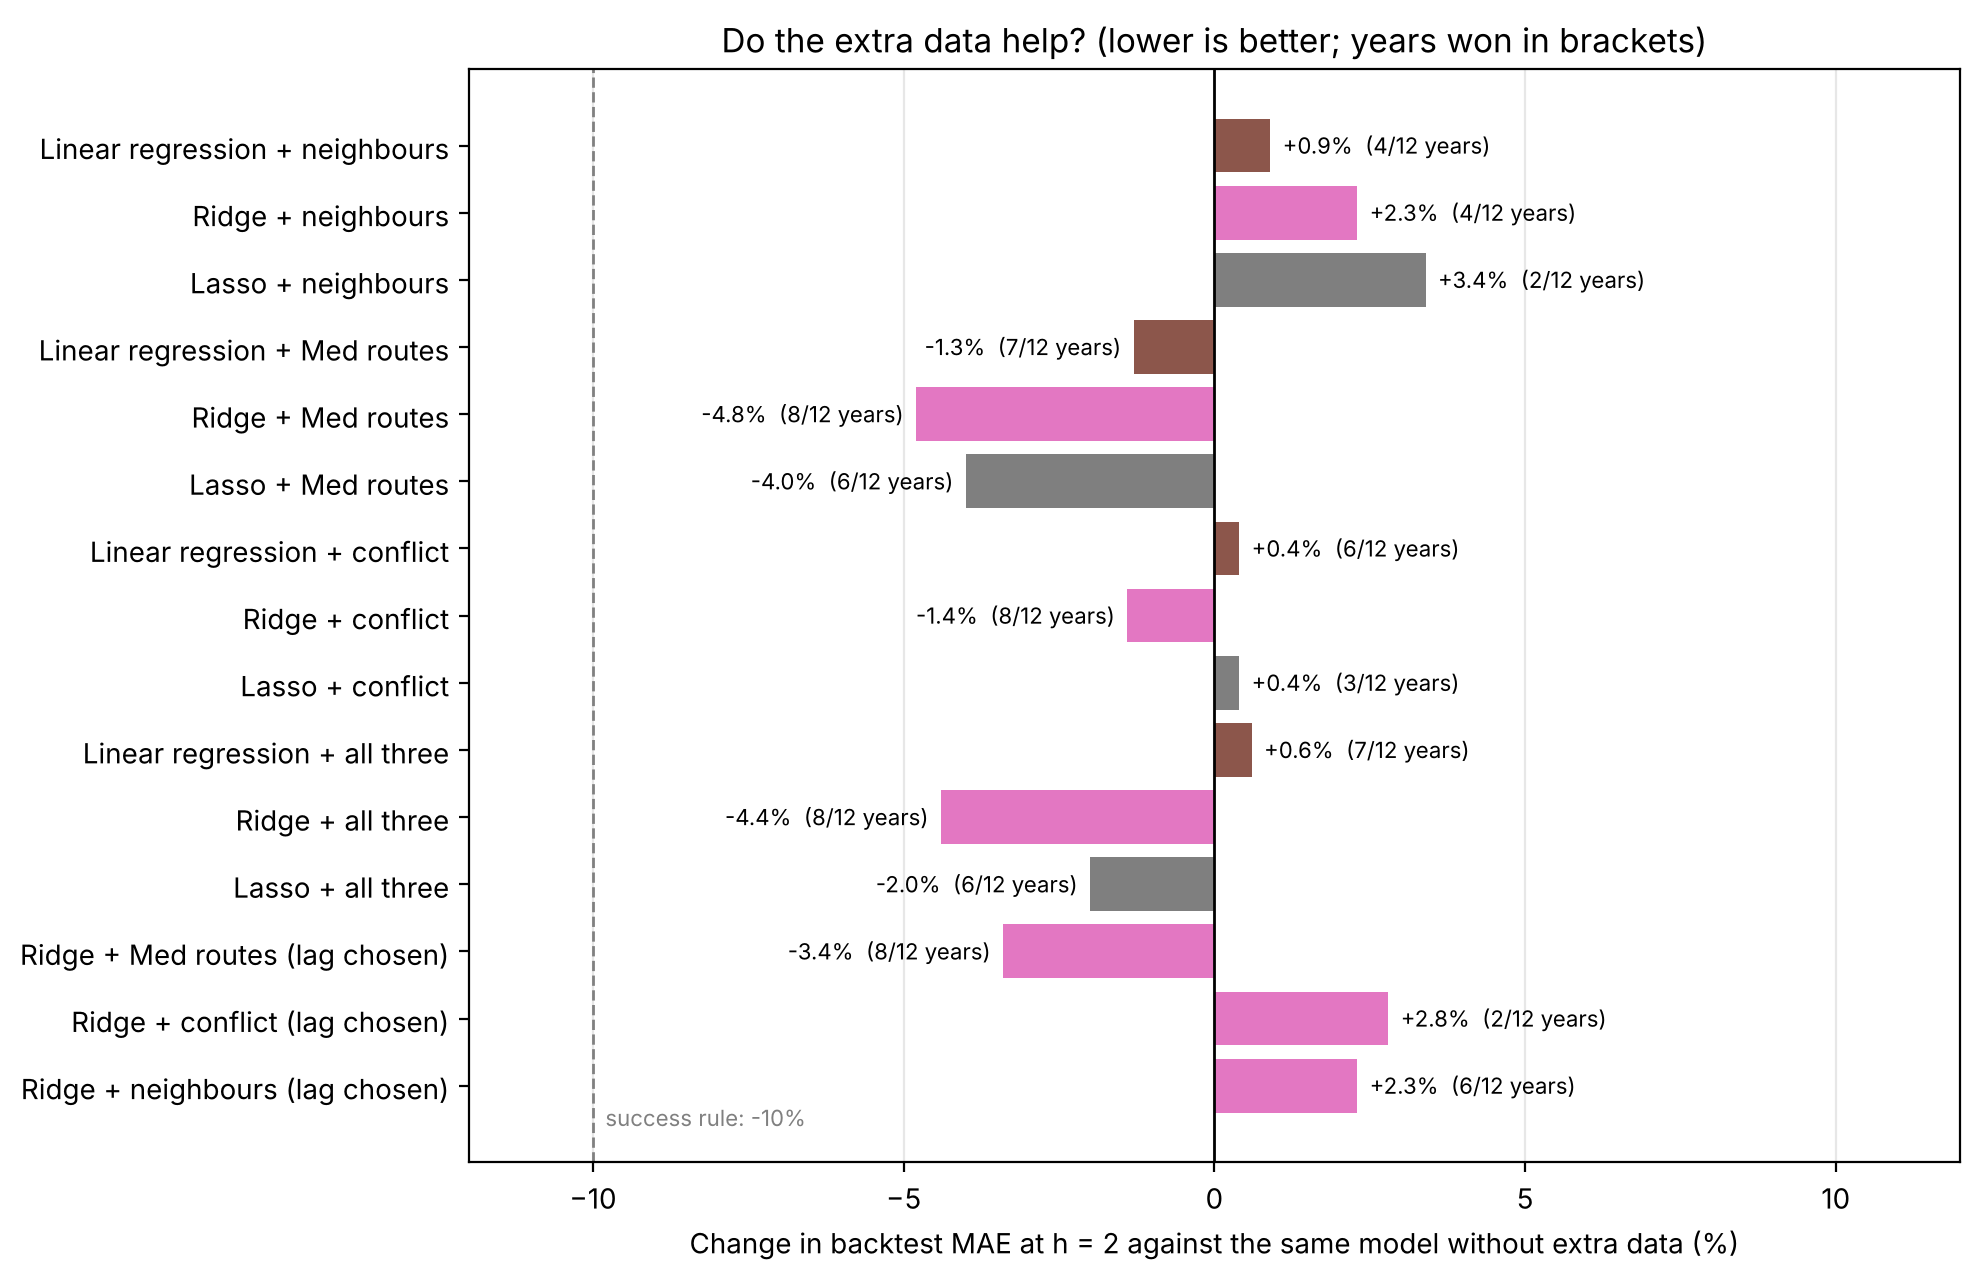

In [9]:
labels, values, colours = [], [], []
for a, b in pairs:
    labels.append(a)
    values.append(year_table.loc[a, "change in MAE (%)"])
    colours.append(plt.cm.tab10(regression_models.index(b) + 5))     # same colours as in 03 (regressions 5, 6, 7)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(range(len(labels)), values, color=colours)
for i, a in enumerate(labels):
    ax.text(values[i] + (0.2 if values[i] >= 0 else -0.2), i, f"{values[i]:+.1f}%  ({year_table.loc[a, 'years won (of 12)']}/12 years)",
            va="center", ha="left" if values[i] >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(-10, color="grey", linestyle="--", linewidth=1)
ax.text(-9.8, len(labels) - 0.4, "success rule: -10%", color="grey", fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(-12, 12)
ax.set_xlabel("Change in backtest MAE at h = 2 against the same model without extra data (%)")
ax.set_title("Do the extra data help? (lower is better; years won in brackets)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/06_extra_data_effect_h2.png")
plt.show()

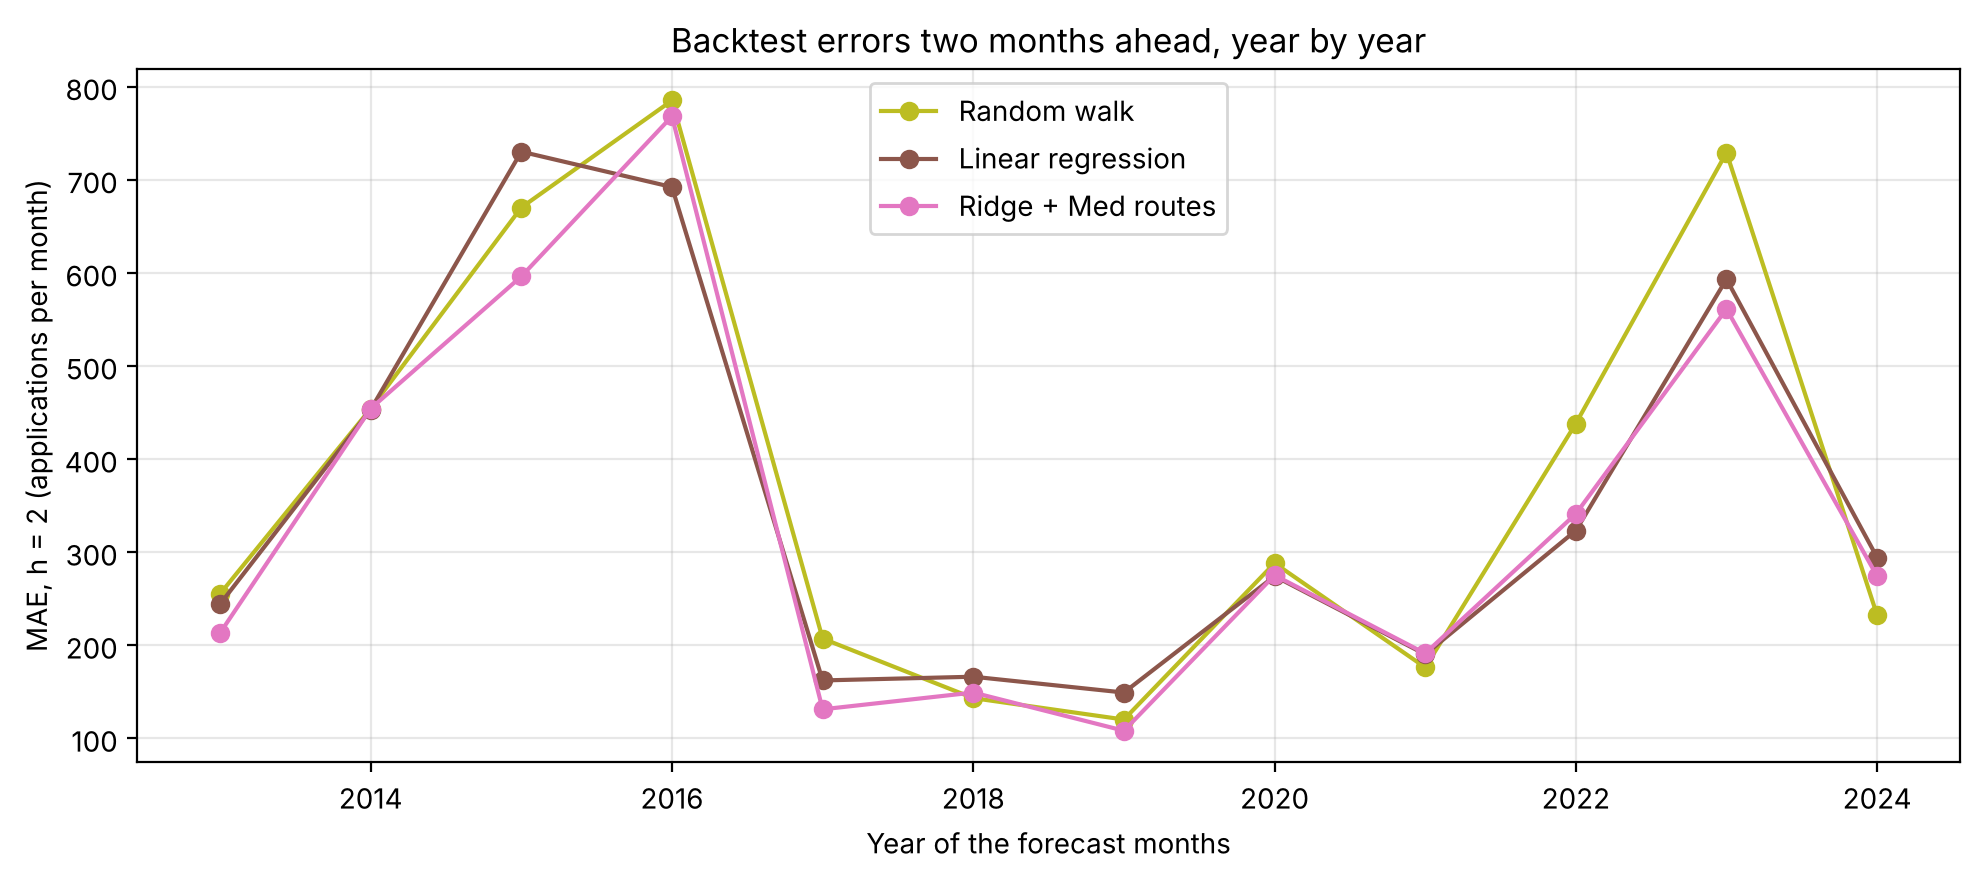

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, colour in [("Random walk", plt.cm.tab10(8)), ("Linear regression", plt.cm.tab10(5)),
                     ("Ridge + Med routes", plt.cm.tab10(6))]:
    ax.plot(by_year.index, by_year[name], marker="o", color=colour, label=name)
ax.set_xlabel("Year of the forecast months")
ax.set_ylabel("MAE, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead, year by year")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/06_errors_by_year_h2.png")
plt.show()

**What we see.** In the first figure, the bars of the neighbours lie right of 0 for all three models, and the bars of the routes and of "all three" left of 0 for Ridge and Lasso; every bar stays far from the dashed line of the success rule. In the second figure, the random walk is worst in the years of fast change (2015, 2022, 2023), where starting from the last month is not enough; in calm years (2018, 2019, 2024) it is as good as or better than the linear regression. Ridge + Med routes is lowest of the three in 2013, 2015, 2017, 2019 and 2023, but the three lines stay close.

## Summary

- **Random walk (added after the test):** MAE 379 at $h = 2$, much better than the 12-month average (528). Our linear regression is 5.4% better and wins in 7 of 12 years, so against this rule our success rule would **not** be met in the backtest; in the test period the regression is 30% better (188 against 269). Against the planned simple rules the success rule is met (−32%, 9 of 12 years).
- **Extra data (one block at a time):** no block meets the success rule. The neighbours make the forecasts worse at $h = 2$. The conflict index changes little. The Mediterranean routes at the UNHCR timing are the only block that helps consistently (Ridge −4.8% at $h = 2$, better at all horizons, 8 of 12 years), but the gap (17 persons) is small against the spread across years (about 220).
- **All three blocks:** about as good as the routes alone with Ridge; worse with the linear regression (overfitting).
- **Lag chosen in each window:** keeps the small gain of the routes, not of the other blocks.
- **Lesson:** applications in the neighbouring countries move at the same time as Swiss applications, conflicts move long before; only information that arrives a little earlier (the routes, one month sooner) helps a little. **Our choice stays the linear regression on the series' own past.**